# HOMEWORK 10

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW10

In this homework, you are going to use and compare two different trackers (of your liking) and compare the results.

In [1]:
# # Silent installation or update
#
# # Clean cache
# !python3 -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !bash -c "python3 -m pip install -U '{package_name}' -q"
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-python",
#     "opencv-contrib-python",
#     "moviepy",
#     "ultralytics",
# ]
#
# for package_name in package_array:
#     !bash -c "python3 -m pip show '{package_name}' > /dev/null 2>&1 || python3 -m pip install -U '{package_name}' -q"


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input videos
# hm_version = 10
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone videos
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name, ".git", ".idea"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"
#
# # Note. To upload big files to GitHub, execute the next command in the terminal
# # 1. brew install git-lfs
# # 2. git lfs install
# # 3.1. git lfs track "*.safetensors"
# # 3.2. git lfs track "*.bin"

### Step 1

Decide what video you are going to use for this homework, select an object and generate the template. You can use any video you want (your own, from Youtube, etc.)
and track any object you want (e.g. a car, a pedestrian, etc.).

In [3]:
# Load data

import cv2
import apps.reporter as rpt
from pathlib import Path
from moviepy import VideoFileClip
from IPython.display import Video

# Input data
file_name = "resources/videos/Doha_Qatar_Dashcam_Drive.mp4"

# Solution
file_path_input = Path(file_name)
file_path_output = file_path_input.with_suffix(".webm")

# Load data
if not file_path_output.exists():
    if file_path_input.exists():
        # convert video in necessary format
        clip = VideoFileClip(file_path_input)
        clip.write_videofile(file_path_output, codec="libvpx")
        clip.close()
    else:
        raise FileNotFoundError("File doesn't exist!")

# Analysis video
video = cv2.VideoCapture(file_path_output)

# check if the video can open
if video.isOpened():
    width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = video.get(cv2.CAP_PROP_FPS)
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = total_frames / fps if fps > 0 else 0
else:
    raise ValueError('Incorrect input data "video"!')

# memory release
# video.release()

rp = rpt.Reporter()
rp.tolerance = 2
rp.add_item("Source of the video", rp.format_link("https://www.youtube.com/watch?v=xX31l9Us1TA"))
rp.add_item("(width, height)", str((width, height)))
rp.add_item("FPS", rp.format_value(fps))
rp.add_item("Total frames", str(total_frames))
rp.add_item("Duration, seconds", rp.format_value(duration))

# Print results
rp.print_pd_report("Video metadata")

Video(file_path_output, embed=False, html_attributes="controls width=720")


Attribute,Result
Source of the video,https://www.youtube.com/watch?v=xX31l9Us1TA
"(width, height)","(854, 480)"
FPS,30.00
Total frames,5250
"Duration, seconds",175.00


In [12]:
# Detection

import cv2
import itertools
import numpy as np
import apps.reporter as rpt
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Input data
car_id = 1
classes = [2]  # for car type is 2
conf = 0.4
thickness = 5
color_palette_name = 'tab20'
car_init_box_xyxy = None
car_init_box_xywh = None
car_init_color = None

# Solution
ret, first_frame = video.read()
assert ret

# get colors map
cmap = (np.asarray(plt.get_cmap(color_palette_name).colors) * 255).astype(int).tolist()  # type: ignore
# extract colors and convert
colors = itertools.cycle(tuple(color) for color in cmap)

# Convert it to RGB
first_frame_rgb = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)
first_frame_dt = first_frame_rgb.copy()

model = YOLO('resources/models/yolov8s.pt')
results = model(first_frame_rgb, classes=classes, conf=conf, verbose=False)
# get car coordinates
car_boxes_xyxy = results[0].boxes.xyxy.cpu().numpy().astype(int)

# draw rectangle over the cars
for idx, car_box_xy in enumerate(car_boxes_xyxy):
    # extract coordinates
    x1, y1, x2, y2 = car_box_xy
    # get color
    current_color = next(colors)
    # draw rectangle
    cv2.rectangle(first_frame_dt, (x1, y1), (x2, y2), current_color, thickness)
    # save coordinates
    if idx == 1:
        car_init_box_xyxy = car_box_xy
        car_init_box_xywh = np.asarray([x1, y1, x2 - x1, y2 - y1])
        car_init_color = current_color

rp = rpt.Reporter()
rp.add_item("Car ID", str(car_id))
rp.add_item("Car coordinates (x1, y1, x2, y2)", str(car_init_box_xyxy))
rp.add_item("Car coordinates (x, y, w, h)", str(car_init_box_xywh))

# Print results
rp.print_pd_report("Bounding Box")

images_dict = {
    "First frame": first_frame_rgb,
    "Detected cars": first_frame_dt,
}


Attribute,Result
Car ID,1
"Car coordinates (x1, y1, x2, y2)",[284 197 530 433]
"Car coordinates (x, y, w, h)",[284 197 246 236]


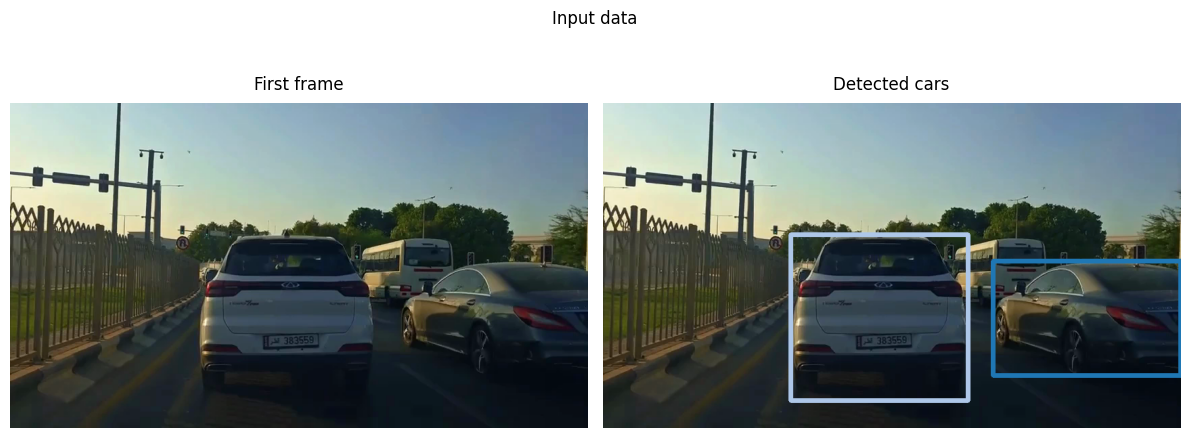

In [5]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 2
images_dict = images_dict
n_img_rows = math.ceil(len(images_dict) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 5 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_dict.items()):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_dict), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("Input data")
plt.tight_layout()
plt.show()


### Step 2

Initialize a tracker (e.g. KCF).

### Step 3

Run the tracker on the video and the selected object. Run the tracker for around 10-15 frames.

### Step 4

For each frame, print the bounding box on the image and save it.

In [ ]:
# Tracker KCF

import cv2

# Input data

# Solution

# Print results


### Step 5

Select a different tracker (e.g. CSRT) and repeat steps 2, 3 and 4.

### Step 6

Compare the results:
* Do you see any differences? If so, what are they?
* Does one tracker perform better than the other? In what way?

### Conclusion
1. A